# Examine Analysis: 

Notebook that used the classes from attpc_analysis for the analysis notebooks

In [ ]:
from spyral_utils.nuclear import NuclearDataMap
from spyral_utils.nuclear.target import SolidTarget, GasTarget, load_target
from spyral_utils.constants import AMU_2_MEV
from pathlib import Path
import numpy as np
import polars as pl

from spyral_utils.plot.histogram import Histogrammer
import matplotlib.pyplot as plt 

%matplotlib widget
plt.close("all")
# Import the ion chamber properties 
nuclear_map = NuclearDataMap()


# This is for the meantime -------------------------------------------------------
# The final motivation is to make it pip installeable 
import sys
src_path = Path.cwd().parents[1]
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))
# --------------------------------------------------------------------------------
from attpc_analysis.src.load.io import RunSolverDataLoader, RunEstimationDataLoader
from attpc_analysis.src.data_models.physics import DataReactionKinematics
from attpc_analysis.src.detector_settings.energy_loss_setup import EnergyLossSetup

# Import the ion chamber properties 
nuclear_map = NuclearDataMap()


Load event from jason file

In [ ]:
from json import load
exp_tag = "a2066"
nuclear_map = NuclearDataMap()
path_to_config = Path(f"../../notebooks/input_parameters/{exp_tag}.json")
with open(path_to_config,"r") as json_file:
    json_data = load(json_file)
    # Get keys from json and use them as their variables 
    workspace_path = Path(json_data["workspace_path"])
    trace_path = Path(json_data["trace_path"])
    target_material_path = Path(json_data["target_path"])
    run_min = json_data["run_min"]
    run_max = json_data["run_max"]
    runs_to_skip = json_data["runs_to_skip"]
    ejectile = nuclear_map.get_data(json_data["ejectile"][0], json_data["ejectile"][1])
    projectile = nuclear_map.get_data(json_data["projectile"][0], json_data["projectile"][1])
    target = nuclear_map.get_data(json_data["target"][0], json_data["target"][1])
    ic_pressure = json_data["ic_pressure"]
    proj_energy_accel = json_data["beam_energy"]
    ic_min_val = json_data["ic_min_val"]
    ic_max_val = json_data["ic_max_val"]
solver_result_path = workspace_path / "InterpSolver"

# We calculate the residual for you
residual_z = target.Z + projectile.Z - ejectile.Z
residual_a = target.A + projectile.A - ejectile.A

if residual_z < 0:
    raise Exception(f"Illegal nuclei! Residual Z: {residual_z}")
if residual_a < 1:
    raise Exception(f"Illegal nuclei! Residual A: {residual_a}")

residual = nuclear_map.get_data(residual_z, residual_a)

In [ ]:
# Get the beam energy for the active area of the detector
energy_loss_setup = EnergyLossSetup(
    beam_energy = proj_energy_accel,
    projectile = projectile,
    attpc_target_path_json= target_material_path
)

target_material = energy_loss_setup.active_gas_target_material()
proj_energy_start = energy_loss_setup.beam_energy_entrance_attpc()
proj_energy_stop = energy_loss_setup.beam_energy_exit_attpc()

print(f"Reaction: {target}({projectile}, {ejectile}){residual}")
print(f"Target material: {target_material.ugly_string}")
print(f"Accelerator Beam energy: {proj_energy_accel} MeV")
print(f"Beam energy range in AT-TPC: {proj_energy_start}-{proj_energy_stop} MeV")

Reaction: 2H(7Be, 4He)5Li
Target material: (Gas)1H2
Accelerator Beam energy: 98 MeV
Beam energy after IC (2 windows + gas): 91.78063208242263 MeV
Beam energy range in AT-TPC: 90.98393316575734-85.01647718866724 MeV


In [31]:
# This is for the meantime -------------------------------------------------------
# The final motivation is to make it pip installeable 
import sys
src_path = Path.cwd().parents[1]
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))
# --------------------------------------------------------------------------------
from attpc_analysis.src.load.io import RunSolverDataLoader, RunEstimationDataLoader
from attpc_analysis.src.data_models.physics import DataReactionKinematics




# Date storage
results = {}
results["run"] = np.empty(0,float)
results["event"] = np.empty(0,float)
results["ex"] = np.empty(0,float)

grammer = Histogrammer()
grammer.add_hist1d("ex", 200,(-2,30))


# Load class with general details of the runs
empty_files = []
solver_data = RunSolverDataLoader(
                solver_result_path=solver_result_path, 
                particle=ejectile,
                empty_files = empty_files
                )

for run in range(run_min, run_max+1):
    df = solver_data.load_solver(run)
    if df is None: continue 
    #------------------------------------------------------------------------------
    # Insert specific filters into the dataframe 
    # (Here)
    #------------------------------------------------------------------------------
    kinematics = DataReactionKinematics(
        data = df, 
        projectile= projectile, 
        target = target, 
        targetlike = ejectile, 
        beamlike = residual, 
        beam_energy_entrace_tpc= proj_energy_start, 
    )
    # Clear data frame
    df = None 
    
    #------------------------------------------------------------------------------
    # Do other things: example missing mass 
    # Insert specific actions that will be saved in arrays
    beamlike_vector = kinematics.missing_mass_technique(target_material)
    ex = beamlike_vector.mass - residual.mass
    #------------------------------------------------------------------------------

    # Save information 
    results["run"] = np.append(results["run"],np.full(len(ex),run))
    results["event"] = np.append(results["event"], ex)
    results["ex"] = np.append(results["ex"],ex)


    # fill histograms 
    grammer.fill_hist1d("ex",ex)

print("Files without data", empty_files)


Files without data [52, 59, 60, 61, 62, 63, 64, 66]


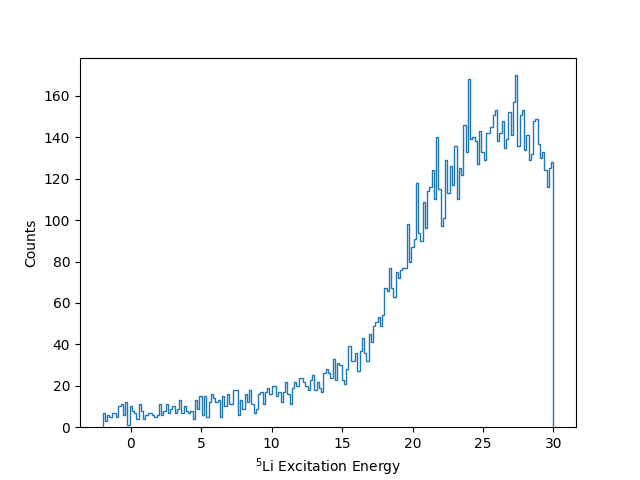

In [32]:
fig, ax = plt.subplots(1,1)
hist = grammer.get_hist1d("ex")
ax.stairs(hist.counts,edges=hist.bins)
ax.set_xlabel(f"{residual.get_latex_rep()} Excitation Energy ")
ax.set_ylabel(f"Counts")
fig.savefig("delete1.png")